# 7 · A luma residual upscaler

The eye resolves fine detail in brightness (luma) far better than in colour - which is why
video sends colour at a quarter of the resolution and nobody notices. This model spends
all of its work on brightness:

- **Colour is bicubic.** The bicubic skip makes the whole picture, as in
  `03_upscale_web.ipynb`, and the network never changes the colour.
- **The network corrects brightness only**, with residual blocks: a deeper body inside the
  same 4-pixel halo.

Steps:

1. **Data** - load the patch pairs.
2. **Model** - bicubic as a fixed convolution, plus a learned brightness correction.
3. **Speed** - is it fast enough for a live stream? Checked before training.
4. **Train** - and compare with bicubic after every epoch.
5. **Save** - write a checkpoint, check it loads back the same, run a whole frame.
6. **Export** - float32 and float16 at the client's tile, float16 as a whole frame.

Needs: `00_data_preprocess.ipynb`. Results: `summary.md`, "The luma residual model".
Writes `checkpoints/upscale_luma.pt`.

In [2]:
"""Settings."""

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

from helpers import metrics, models, speed, tiles, training, webexport
from helpers.training import DATA_DIR, DEVICE

CHECKPOINT = training.CHECKPOINT_DIR / "upscale_luma.pt"
# the same model and recipe as notebook 4's "luma 24 + 2 blocks", so the two share one training
# (see "4. Train"); change the network and give it a file of its own
TRAINING = training.CHECKPOINT_DIR / "strategy_runs" / "luma_24_2_blocks_seed0_lr0.001.pt"
FRAME_DIR = DATA_DIR / "synthetic"

# The network (see "2. Model")
WIDTHS = (24,)       # channels of the plain convolutions before the blocks
BLOCKS = 2           # residual blocks, at the last width
STEM = 3             # kernel size of the first convolution
SKIP = 5             # kernel size of the bicubic skip (bicubic x2 needs 4 taps; 5 is the smallest odd size)
MAX_EPOCHS = 500     # a safety limit; training stops once it has converged
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
SEED = 0

BENCH_RESOLUTIONS = [(480, 270), (640, 360), (960, 540), (1280, 720)]   # LR input sizes
STEP_WIDTH, STEP_HEIGHT = 320, 180       # LR pixels one client tile adds to the picture (notebook 5)
FRAME_WIDTH, FRAME_HEIGHT = 1920, 1080   # the whole-frame graph
NAME = "luma_24x2"

training.seed_everything(SEED)

## 1. Data

`train` is what the model learns from, with random flips and rotations as free extra
examples. `val` is held out: every score below is measured on it.

The LR patches carry a halo of extra pixels, so the model's output is a bit too large;
`trim` cuts that border off before the loss and the scores.

device  cuda NVIDIA GeForce RTX 3090
scale   2
patch   72 px LR in (64 px + a halo of 4) -> 128 px HR out, 8 frames each
train  17140 patches from 1089 sources
val     3523 patches from 225 sources
lr batch (32, 3, 72, 72)  hr batch (32, 3, 128, 128)


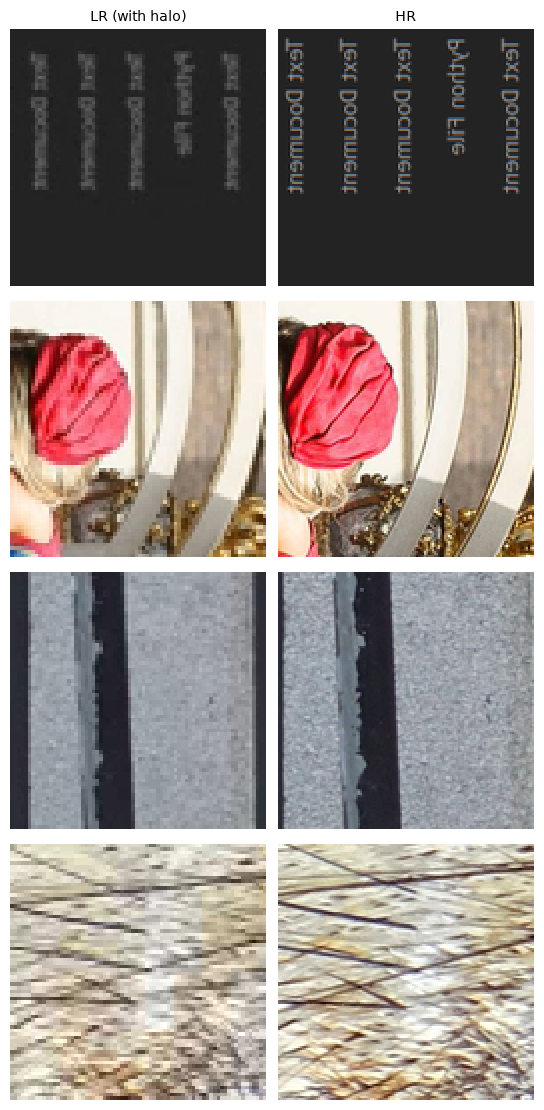

In [3]:
manifest = training.load_manifest()
training.describe(manifest)
SCALE = manifest["scale"]
train_loader, val_loader = training.loaders(DATA_DIR, manifest, BATCH_SIZE)
trim = training.trimmer(manifest)

lr_batch, hr_batch = next(iter(train_loader))
print("lr batch", tuple(lr_batch.shape), " hr batch", tuple(hr_batch.shape))
training.show_patches({"LR (with halo)": lr_batch[:4], "HR": hr_batch[:4]})

## 2. Model

    LR --> bicubic skip (fixed 5x5 conv) ---------------------------------------------------------+
    LR --> conv 3x3 -> ReLU -> residual block x2 -> output conv 3x3 -> same value for R, G, B --+--> add --> PixelShuffle --> HR

- **Brightness only.** The output convolution makes one correction for each of the
  `scale²` HR pixels of an LR pixel, and the same value is added to R, G and B. In BT.709
  that moves Y by exactly that value and leaves Cb and Cr as bicubic made them: the colour
  cannot drift, and nothing is spent on detail the eye barely sees.
- **Residual blocks.** Each is 3x3 -> ReLU -> 1x1, with its input added back. The 1x1
  reaches no further, so a block costs one pixel of halo, and adding the input back keeps
  a deeper body easy to train.
- **Starts as bicubic.** The output convolution starts at zero, as in notebook 3.

The body reads R, G and B; reading Y alone buys nothing (`summary.md`).

**Halo.** The stem reaches 1, every 3x3 after it 1: 4 in all, within the halo of the
patches and of the client's tiles.

In [4]:
model = models.LumaUpscaler(WIDTHS, BLOCKS, STEM, SKIP, SCALE).to(DEVICE)
assert model.halo <= manifest["halo"], "the model reaches further than the patches' halo"
print(model)
print(f"{models.count_parameters(model, learned_only=True):,} learned parameters, halo {model.halo}, "
      f"{speed.macs_per_lr_pixel(model):,.0f} multiply-adds per LR pixel")

LumaUpscaler(
  (skip): BicubicSkip(
    (conv): Conv2d(3, 12, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), bias=False)
  )
  (shuffle): PixelShuffle(upscale_factor=2)
  (body): Sequential(
    (0): Conv2d(3, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): ResidualBlock(
      (conv): Conv2d(24, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (point): Conv2d(24, 24, kernel_size=(1, 1), stride=(1, 1))
    )
    (3): ResidualBlock(
      (conv): Conv2d(24, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (point): Conv2d(24, 24, kernel_size=(1, 1), stride=(1, 1))
    )
  )
  (tail): Conv2d(24, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
)
13,156 learned parameters, halo 4, 13,932 multiply-adds per LR pixel


In [5]:
"""Colour is untouched: even with random weights, what the network adds has no Cb or Cr."""

probe = models.LumaUpscaler(WIDTHS, BLOCKS, STEM, SKIP, SCALE).to(DEVICE)
with torch.no_grad():
    for weight in probe.parameters():
        if weight.requires_grad:
            weight.normal_(0, 0.1)
    x = torch.rand(2, 3, 40, 40, device=DEVICE)
    added = probe(x) - probe.shuffle(probe.skip(x))   # the output minus bicubic
    colour_change = metrics.rgb_to_yuv(added)[:, 1:].abs().max().item()
print(f"largest colour change with random weights: {colour_change:.1e} (float32 rounding)")

largest colour change with random weights: 1.2e-07 (float32 rounding)


In [6]:
"""Before training: the model must score exactly like bicubic."""

bicubic = models.Resize(SCALE).to(DEVICE)
baseline = training.evaluate(bicubic, val_loader, trim)
start = training.evaluate(model, val_loader, trim)
metrics.print_table({"bicubic": baseline, "untrained model": start})
assert abs(start["rgb"] - baseline["rgb"]) < 1e-3, "the model should start as bicubic"

                     wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
bicubic              34.14    33.18    50.67    51.46     32.02   0.9049
untrained model      34.14    33.18    50.67    51.46     32.02   0.9049


## 3. Speed - is it fast enough?

A model that misses the frame time is no use for a live stream, however good it looks.
Speed depends on the network's shape, not its weights, so it is checked before training:
if it is too slow, change `WIDTHS` and `BLOCKS` now.

In [7]:
"""One frame at a time, at the sizes a client asks for."""

model.eval()
print(f"{'output':>12}{'ms/frame':>10}   fits")
with torch.no_grad():
    for width, height in BENCH_RESOLUTIONS:
        x = torch.rand(1, 3, height, width, device=DEVICE)
        ms = speed.time_ms(lambda: model(x), seconds=1.0)
        print(f"{f'{width * SCALE}x{height * SCALE}':>12}{ms:10.1f}   {speed.frame_budget(ms)}")

      output  ms/frame   fits
     960x540       0.9   60 fps
    1280x720       1.5   60 fps
   1920x1080       3.2   60 fps
   2560x1440       5.7   60 fps


### On the target hardware

As in notebook 3: `webexport.count_work` counts the operations (a multiply-add is 2) and
the memory traffic in the ONNX graph of one client tile, and a frame costs that times its
tiles. The **roofline** estimate gives a device the slower of *operations / peak compute*
and *bytes / bandwidth*. This computer's GPU is timed to see what share of its peak it
reaches, and every device in `speed.HARDWARE` is assumed to reach the same share. A browser
usually reaches less, so read it as a best case.

In [8]:
"""The work in one client tile, and the estimated ms per frame on each device (float32)."""

plan = tiles.plan_tiling((FRAME_WIDTH, FRAME_HEIGHT), scale=SCALE, halo=model.halo)
# into checkpoints/, not dist/, so the benchmark page does not list it
tile_graph = webexport.export(model, "speed_check_luma.onnx", plan["input"][2:], halo=model.halo,
                              models_dir=training.CHECKPOINT_DIR / "speed")
work = webexport.count_work(tile_graph["path"])
ops_per_pixel = work["operations"] / work["input_pixels"]   # every convolution keeps the size
bytes_per_pixel = work["activation_bytes"] / work["input_pixels"]
print(f"per LR pixel: {ops_per_pixel:,.0f} operations, {bytes_per_pixel:,.0f} bytes moved")


def frame_work(width, height):
    """Operations and bytes for one width x height output frame, cut into the client's tiles."""
    plan = tiles.plan_tiling((width, height), scale=SCALE, halo=model.halo)
    pixels = plan["runs"] * plan["input"][2] * plan["input"][3]   # LR pixels computed, halos included
    return {"operations": pixels * ops_per_pixel, "bytes": pixels * bytes_per_pixel + plan["runs"] * work["weight_bytes"]}


# calibrate: the share of its peak this GPU reaches, on one whole 1080p frame (no tiles)
if DEVICE.type == "cuda":
    x = torch.rand(1, 3, FRAME_HEIGHT // SCALE, FRAME_WIDTH // SCALE, device=DEVICE)
    with torch.no_grad():
        measured_ms = speed.time_ms(lambda: model(x), seconds=1.0)
    pixels = x.shape[2] * x.shape[3]
    whole_frame = {"operations": pixels * ops_per_pixel, "bytes": pixels * bytes_per_pixel + work["weight_bytes"]}
    best_ms, _ = speed.roofline_ms(whole_frame, *speed.HARDWARE[speed.THIS_GPU])
    efficiency = best_ms / measured_ms
    print(f"{speed.THIS_GPU}: {measured_ms:.2f} ms per 1080p frame, the roofline says at least {best_ms:.2f} ms, "
          f"so it reaches {efficiency:.0%} of its peak")
else:
    efficiency = 1.0
    print("no GPU here to calibrate on: the estimates below are the roofline itself, a best case")

resolutions = [(width * SCALE, height * SCALE) for width, height in BENCH_RESOLUTIONS]
print(f"\nestimated ms per frame at {efficiency:.0%} of the peak (c = compute-bound, m = memory-bound)")
print(f"{'':<36}" + "".join(f"{f'{width}x{height}':>14}" for width, height in resolutions) + "   1080p")
for name, (tflops, gbps) in speed.HARDWARE.items():
    row = f"{name:<36}"
    for width, height in resolutions:
        best_ms, limit = speed.roofline_ms(frame_work(width, height), tflops, gbps)
        row += f"{best_ms / efficiency:>10.1f} ({limit[0]})"
    full_hd_ms = speed.roofline_ms(frame_work(FRAME_WIDTH, FRAME_HEIGHT), tflops, gbps)[0] / efficiency
    print(f"{row}   {speed.frame_budget(full_hd_ms)}")

per LR pixel: 28,120 operations, 2,536 bytes moved
NVIDIA RTX 3090: 3.22 ms per 1080p frame, the roofline says at least 1.40 ms, so it reaches 44% of its peak

estimated ms per frame at 44% of the peak (c = compute-bound, m = memory-bound)
                                           960x540      1280x720     1920x1080     2560x1440   1080p
Intel UHD 620 (laptop iGPU)               21.1 (c)      37.8 (c)      85.1 (c)     151.3 (c)   under 30 fps
Intel Iris Xe, 96 EU (laptop iGPU)        11.8 (m)      21.1 (m)      47.4 (m)      84.3 (m)   under 30 fps
Apple M1, 8-core GPU                      11.8 (m)      21.1 (m)      47.4 (m)      84.3 (m)   under 30 fps
NVIDIA GTX 1650                            6.3 (m)      11.2 (m)      25.2 (m)      44.8 (m)   30 fps
NVIDIA RTX 3060                            2.2 (m)       4.0 (m)       9.0 (m)      15.9 (m)   60 fps
NVIDIA RTX 3090                            0.9 (m)       1.5 (m)       3.4 (m)       6.1 (m)   60 fps


## 4. Train

Same recipe as `02_upscale_nn.ipynb`: the loss is `metrics.ssim_l1_loss` (0.84 x (1 - SSIM
on luma) + 0.16 x L1 on RGB), and after every epoch the epoch with the best luma SSIM
(`ssim-y`) is kept. Training runs until the score stops improving, halving the learning
rate at every plateau; `MAX_EPOCHS` is only a safety limit.

The training is saved to `TRAINING` after every epoch. This model and recipe are notebook
4's `luma 24 + 2 blocks`, so the two notebooks share that file: whichever runs first trains
it (about 10 minutes on an RTX 3090), and the other just loads it.

The colour columns (`psnr-u`, `psnr-v`) stay exactly at bicubic's: only brightness moves.

Loaded the training saved in /home/henrik/desktop-streamer-ai/src/upscale/checkpoints/strategy_runs/luma_24_2_blocks_seed0_lr0.001.pt: 116 epochs done in 9.0 min, best epoch 98 (val_ssim_y: 0.9286), learning rate now 1.0e-05.
It had finished (converged - no improvement in 6 epochs, even at the smallest learning rate), so nothing is trained again - delete the file to train from the start.
Restoring model weights from the end of the best epoch: 98 (val_ssim_y: 0.9286, +0.0151 over the untrained model). Training took 116 epochs, 9.0 min.


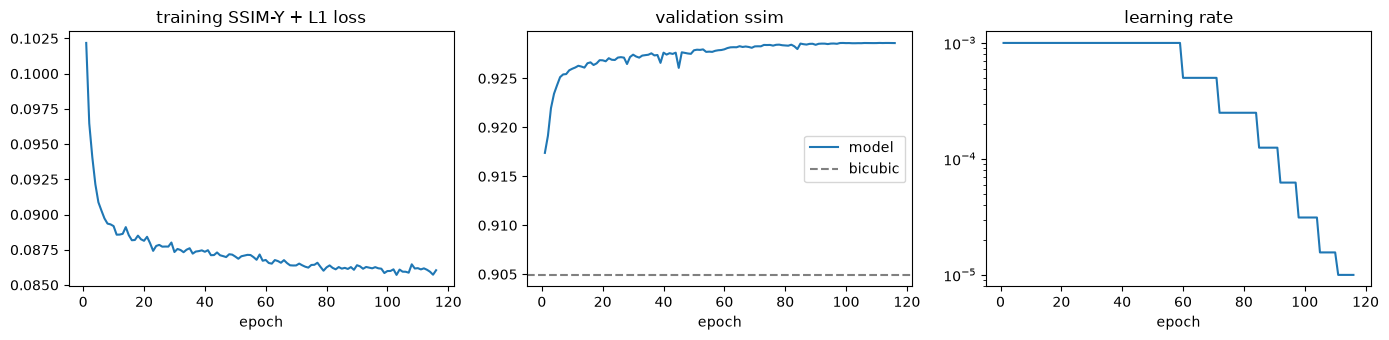

                    wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
bicubic             34.14    33.18    50.67    51.46     32.02   0.9049   +0.0000 ssim-y vs bicubic
model               35.33    34.45    50.70    51.49     32.96   0.9292   +0.0243 ssim-y vs bicubic


In [9]:
history, best = training.train(model, train_loader, val_loader, trim, MAX_EPOCHS, learning_rate=LEARNING_RATE,
                               loss_fn=metrics.ssim_l1_loss, select="ssim", checkpoint=TRAINING)
training.plot_history(history, baseline, key="ssim", loss_name="SSIM-Y + L1 loss")

final = training.evaluate(model, val_loader, trim)
metrics.print_table({"bicubic": baseline, "model": final},
                    extra=lambda name, scores: f"   {scores['ssim'] - baseline['ssim']:+.4f} ssim-y vs bicubic")

### What it looks like

Bicubic, the model and the target. Check text lines and window edges - that is what a
desktop stream is made of.

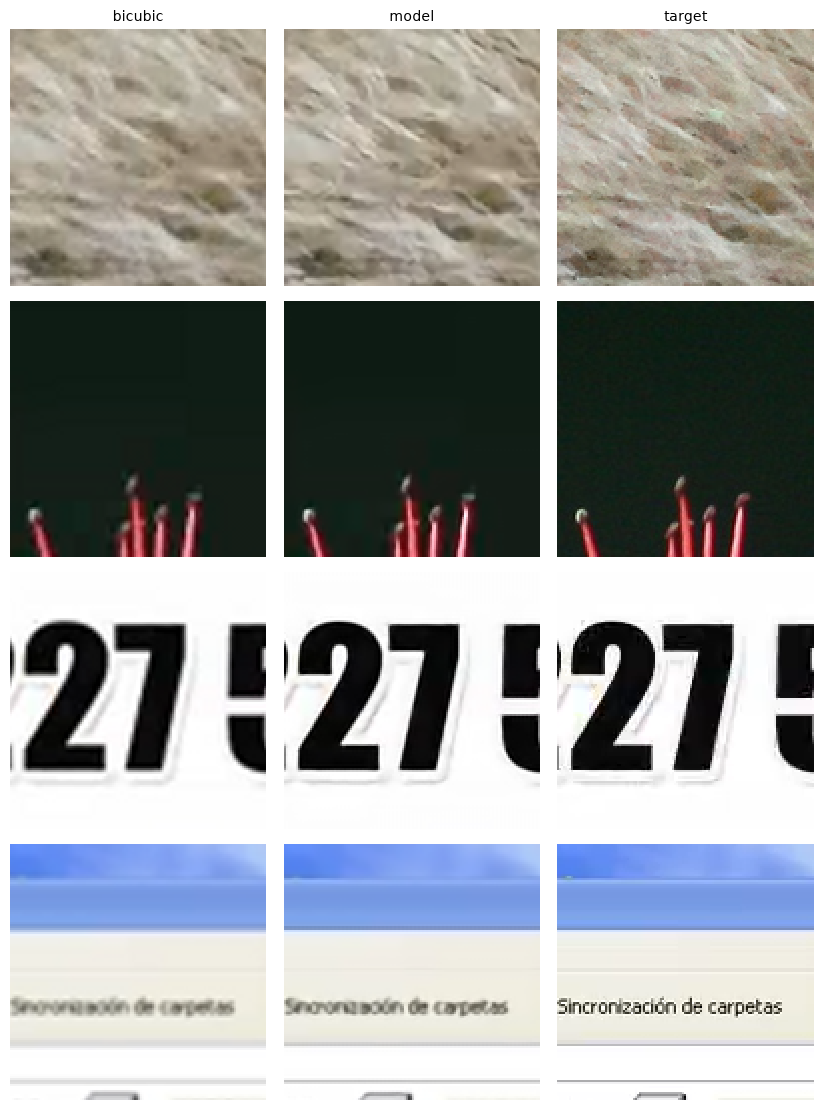

In [10]:
picks = [0, 400, 900, 1600]   # far apart in the set, so from different sources
lr = torch.stack([val_loader.dataset[i][0] for i in picks]).to(DEVICE)
hr = torch.stack([val_loader.dataset[i][1] for i in picks]).to(DEVICE)
with torch.no_grad():
    training.show_patches({
        "bicubic": trim(models.bicubic(lr, SCALE)),
        "model": trim(model.eval()(lr)),
        "target": hr,
    })

## 5. Save and reload

The checkpoint holds the weights *and* everything needed to rebuild the model. We load
it into a fresh model and check it computes the same thing.

In [11]:
training.save_checkpoint(CHECKPOINT, model, architecture="LumaUpscaler",
                         arguments={"widths": WIDTHS, "blocks": BLOCKS, "stem": STEM, "skip": SKIP},
                         scale=SCALE, halo=model.halo, loss="ssim_l1_loss", select="ssim",
                         learning_rate=LEARNING_RATE, epochs=len(history), best_epoch=best["epoch"],
                         val=final, val_bicubic=baseline, degradation=manifest["degradation"])

# rebuild the model from the file alone, the way a later notebook would
checkpoint = training.load_checkpoint(CHECKPOINT)
loaded = models.LumaUpscaler(scale=checkpoint["scale"], **checkpoint["arguments"]).to(DEVICE)
loaded.load_state_dict(checkpoint["state_dict"])
training.assert_same_model(model, loaded)
print("reloaded model is identical")

saved /home/henrik/desktop-streamer-ai/src/upscale/checkpoints/upscale_luma.pt (62 KB)
reloaded model is identical


### A whole frame

The model is fully convolutional, so it runs on a picture of any size, not only patches.

                    wpsnr   psnr-y   psnr-u   psnr-v  psnr-rgb   ssim-y
bicubic             25.82    25.09    29.55    29.01     23.92   0.9437
model               27.68    27.26    29.57    29.02     25.23   0.9656


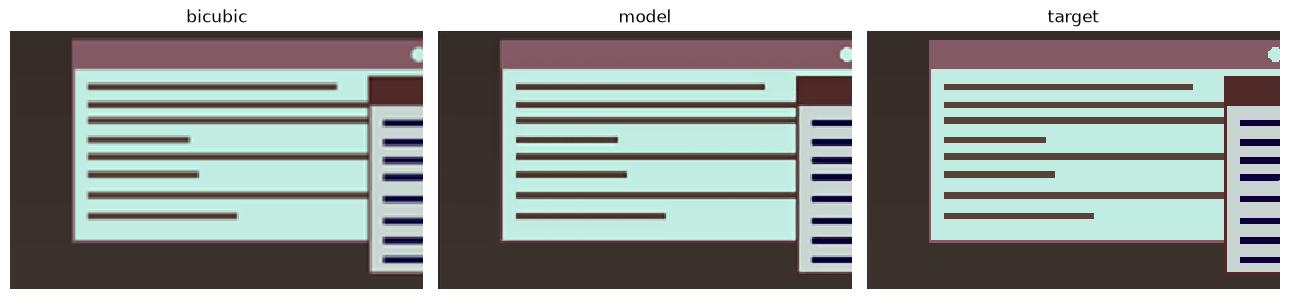

In [12]:
truth = Image.open(sorted(FRAME_DIR.glob("*.png"))[0]).convert("RGB")
truth = truth.crop((0, 0, truth.width - truth.width % SCALE, truth.height - truth.height % SCALE))
small = truth.resize((truth.width // SCALE, truth.height // SCALE), Image.BICUBIC)

with torch.no_grad():
    upscaled = loaded.eval()(training.to_tensor(small))
target = training.to_tensor(truth)
metrics.print_table({"bicubic": metrics.report(models.bicubic(training.to_tensor(small), SCALE), target),
                     "model": metrics.report(upscaled, target)})
Image.fromarray(training.to_image(upscaled)).save(training.SAMPLE_DIR / "upscaled_luma.png")

box = (slice(0, 200), slice(0, 320))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
panels = {"bicubic": np.asarray(small.resize(truth.size, Image.BICUBIC)),
          "model": training.to_image(upscaled), "target": np.asarray(truth)}
for ax, (name, image) in zip(axes, panels.items()):
    ax.imshow(image[box], interpolation="nearest")
    ax.set_title(name)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 6. Export for the browser

At the tile a client runs (a 320x180 step, `05_upscale_geometry.ipynb`): float32, float16
(half the size), and float16 as one whole 1080p frame. Each graph is checked against the
torch model first. It is `Conv`, `Relu`, `Add`, `Concat` and `DepthToSpace` - all inside
the browser's fast operator set.

In [13]:
def input_shape(step_height, step_width, halo):
    """The model input for a step: the step plus the halo on every side, as (height, width)."""
    return (step_height + 2 * halo, step_width + 2 * halo)


def check_and_time(info, module, shape, dtype, tolerance):
    """Check a written graph against the torch module, time it on the CPU, print one line."""
    webexport.check_graph(info["path"], module, np.random.rand(1, 3, *shape).astype(np.float32), dtype, tolerance)
    ms = webexport.time_graph(info["path"], shape, dtype)
    webexport.annotate(info, cpu_ms=round(ms, 2))
    print(webexport.summary_line(info, ms))


tile_name = f"tile{STEP_WIDTH}x{STEP_HEIGHT}"
halo = loaded.halo
tile_shape = input_shape(STEP_HEIGHT, STEP_WIDTH, halo)
frame_shape = input_shape(FRAME_HEIGHT // SCALE, FRAME_WIDTH // SCALE, halo)

fp32 = webexport.export(loaded, f"upscale_{NAME}_{tile_name}.onnx", tile_shape, label=f"{NAME} fp32", halo=halo)
check_and_time(fp32, loaded, tile_shape, np.float32, tolerance=2e-3)

fp16 = webexport.to_float16(fp32, f"upscale_{NAME}_fp16_{tile_name}.onnx")
webexport.write_metadata(fp16["path"], {"label": f"{NAME} fp16"})
check_and_time(fp16, loaded, tile_shape, np.float16, tolerance=4e-3)

frame = webexport.to_frame(fp16, f"upscale_{NAME}_fp16_{tile_name}_frame.onnx", FRAME_WIDTH, FRAME_HEIGHT)
check_and_time(frame, loaded, frame_shape, np.float16, tolerance=4e-3)
print("compare in a browser: uv run src/upscale/benchmark/main.py")

upscale_luma_24x2_tile320x180.onnx                     57.6 KB    3.92 ms   Addx3, Concatx1, Convx7, DepthToSpacex1, Relux3
upscale_luma_24x2_fp16_tile320x180.onnx                31.0 KB    4.19 ms   Addx3, Concatx1, Convx7, DepthToSpacex1, Relux3
upscale_luma_24x2_fp16_tile320x180_frame.onnx          31.0 KB   45.38 ms   Addx3, Concatx1, Convx7, DepthToSpacex1, Relux3
compare in a browser: uv run src/upscale/benchmark/main.py
